---
title: "L3-02 · Vectors and inner products"
short_title: "Vectors and inner products"
subtitle: "The inner product measures how much of one vector lies along another: for a unit vector it is the signed length of a shadow, it never exceeds the product of the lengths, and for complex entries it needs a conjugate so that every nonzero vector has positive length."
description: "Normalize a real or complex vector, compute inner products with the conjugate in the right place, and use an orthonormal basis to expand a vector and read off squared overlaps."
tags: [level-3, coursebook]
---

(lesson-l3-02)=

:::{div}
:class: qcai-meta
![Level 3 icon](../../_static/icons/qicon-level-3.svg) **Level 3 · High-school bridge** · about 90 minutes  
**Big idea.** The inner product measures how much of one vector lies along another: for a unit vector it is the signed length of a shadow, it never exceeds the product of the lengths, and for complex entries it needs a conjugate so that every nonzero vector has positive length.  
**Before this lesson.** [L3-01](#lesson-l3-01)  
**Lab.** [Qubits and the Bloch sphere](../../labs/05-qubit-bloch.ipynb)
:::

## What you will be able to do

- Compute $\|v\|$ and the normalized vector $v/\|v\|$ for real and complex vectors, and the inner product $\langle u, v\rangle = \sum_j \bar u_j v_j$.
- Interpret $\langle u, v\rangle$ for a unit vector $u$ as the signed length of the shadow of $v$ on the line of $u$, and find the projection and the orthogonal remainder.
- State and prove the Cauchy-Schwarz inequality $|\langle u, v\rangle| \le \|u\|\,\|v\|$, and use it to define the angle between real vectors.
- Expand a vector in an orthonormal basis, check $\sum_k |\langle e_k, v\rangle|^2 = \|v\|^2$, and say when a squared overlap can be read as a probability.

## Why this matters

Here is a puzzle. The vector $(1, i)$ is clearly not the zero vector, yet if you compute its squared length the way you would for a real vector, $1^2 + i^2 = 1 - 1 = 0$. A length formula that gives zero for a nonzero vector is useless. Something has to change when vectors have complex entries, and the fix (one complex conjugate, placed in the right slot) is a convention that every later quantum lesson relies on.

The second reason to care is that almost every question you will ask about a state vector is an inner product. How much of this signal lies along that pattern? How similar are two word embeddings? What is the chance that a qubit prepared one way passes a test for another? Each answer is a number $\langle u, v\rangle$, and the Cauchy-Schwarz inequality guarantees that such numbers stay within the bounds the lengths allow. This lesson builds the picture first, a shadow on a line, and then the algebra that carries the picture into complex spaces.

:::{dropdown} Key terms

**Norm**
: The length $\|v\| = \sqrt{\langle v, v\rangle}$ of a vector; for real entries $\sqrt{v_1^2 + \dots + v_n^2}$, for complex entries $\sqrt{|v_1|^2 + \dots + |v_n|^2}$.

**Unit vector**
: A vector of norm 1. Dividing a nonzero vector by its norm normalizes it without changing its direction.

**Inner product**
: $\langle u, v\rangle = \sum_j \bar u_j v_j$: conjugate the entries of the first vector, multiply entry by entry, add.

**Orthogonal**
: Two vectors with $\langle u, v\rangle = 0$.

**Projection**
: For a unit vector $u$, the vector $\langle u, v\rangle\, u$: the part of $v$ that lies along $u$.

**Orthonormal basis**
: A basis $e_1, \dots, e_n$ of unit vectors that are pairwise orthogonal, $\langle e_j, e_k\rangle = \delta_{jk}$.

:::


In [1]:
import sys, pathlib, subprocess
here = pathlib.Path.cwd()
root = next((p for p in [here, *here.parents] if (p / "qcai").is_dir()), None)
if root is None:  # for example on Google Colab: fetch the course's small teaching package
    root = pathlib.Path("quantum-causal-ai")
    if not root.exists():
        subprocess.run(["git", "clone", "--depth", "1", "https://github.com/pozapas/quantum-causal-ai.git", str(root)], check=True)
    root = root.resolve()
sys.path.insert(0, str(root))
from qcai.viz import show as _show, show_mpl as _show_mpl
from qcai.lessonfigs import l3_02 as _lessonfigs

## Length and direction

A vector in $\mathbb{R}^n$ or $\mathbb{C}^n$ is an ordered list of $n$ numbers. Each position names a basis direction, so the order matters. In two real dimensions a vector $v = (v_1, v_2)$ is an arrow from the origin to the point $(v_1, v_2)$, exactly as in [L2-09](#lesson-l2-09). We build every idea on that picture first and carry it to complex entries in the third section [@openstax_vectors; @mml].

:::{prf:definition} Norm and normalization
:label: def-l3-02-norm
The **norm** of $v \in \mathbb{C}^n$ is $\|v\| = \sqrt{|v_1|^2 + \dots + |v_n|^2}$. For real entries $|v_j|^2 = v_j^2$. A **unit vector** has norm 1. If $v \ne 0$, the vector $\hat v = v / \|v\|$ is the **normalization** of $v$: it points the same way and has norm 1.
:::

$$
\|v\| = \sqrt{|v_1|^2 + |v_2|^2 + \dots + |v_n|^2}, \qquad \hat v = \frac{v}{\|v\|}
$$ (eq-l3-02-norm)

For $v = (3, 4)$, equation [](#eq-l3-02-norm) gives $\|v\| = \sqrt{3^2 + 4^2} = \sqrt{25} = 5$ and $\hat v = (3/5, 4/5) = (0.6, 0.8)$. Check: $0.36 + 0.64 = 1$. Normalizing slides the tip of the arrow along its own line until it lands on the unit circle; the direction does not change because we divided by a positive number.

## The dot product as a shadow

:::{prf:definition} Dot product of real vectors
:label: def-l3-02-dot
For $u, v \in \mathbb{R}^n$, $\; u \cdot v = u_1 v_1 + u_2 v_2 + \dots + u_n v_n$. In particular $v \cdot v = \|v\|^2$.
:::

$$
u \cdot v = \sum_{j=1}^{n} u_j v_j = \|u\|\,\|v\|\cos\theta
$$ (eq-l3-02-dot)

The second equality in [](#eq-l3-02-dot), with $\theta$ the angle between the arrows, is the law of cosines in disguise: expand $\|v - u\|^2 = \|u\|^2 + \|v\|^2 - 2\,u\cdot v$ and compare with $\|u\|^2 + \|v\|^2 - 2\|u\|\|v\|\cos\theta$. Its geometric reading is the key picture of this lesson. If $u$ is a **unit** vector, $u \cdot v = \|v\|\cos\theta$ is the signed length of the shadow that $v$ casts on the line through $u$ when light falls perpendicular to that line.

:::{figure} ../../_static/animations/l3_02_projection.mp4
:alt: The arrow v = (3, 4) of length 5 shrinks onto the unit circle at (0.6, 0.8); then it casts a shadow of length 4.8 on the line of the unit vector u = (0.8, 0.6), with a leftover piece of length 1.4 at right angles.
:width: 100%

Normalize, then project: $\hat v = (0.6, 0.8)$, and the shadow of $v = (3, 4)$ on $u = (0.8, 0.6)$ has length $\langle u, v\rangle = 4.8$.
:::

:::{dropdown} What the animation shows
The animation draws $v = (3, 4)$ and computes $\|v\| = \sqrt{3^2 + 4^2} = 5$. The arrow then shrinks along its own line onto the unit circle, ending at $\hat v = (0.6, 0.8)$. The full arrow returns and the unit vector $u = (0.8, 0.6)$ appears with the line through it. A dashed perpendicular drops from the tip of $v$ to that line; the shadow from the origin to the foot is highlighted and labeled $\langle u, v\rangle = 0.8 \cdot 3 + 0.6 \cdot 4 = 4.8$. The leftover piece from the foot to the tip of $v$ has length 1.4 and meets the line at a right angle, and the screen checks $4.8^2 + 1.4^2 = 25 = \|v\|^2$.
:::

:::{prf:proposition} Projection on a unit vector
:label: prop-l3-02-projection
Let $u$ be a unit vector and $v$ any vector in $\mathbb{R}^n$. Put $p = (u \cdot v)\,u$ and $r = v - p$. Then $u \cdot r = 0$ and $\|v\|^2 = (u\cdot v)^2 + \|r\|^2$.
:::

:::{prf:proof}
$u \cdot r = u \cdot v - (u\cdot v)(u \cdot u) = u\cdot v - u \cdot v = 0$ because $u \cdot u = 1$. Since $p$ is a multiple of $u$, also $p \cdot r = 0$. Then $\|v\|^2 = (p + r)\cdot(p + r) = \|p\|^2 + 2\,p\cdot r + \|r\|^2 = (u\cdot v)^2 + \|r\|^2$.
:::

With $v = (3, 4)$ and $u = (0.8, 0.6)$: $u \cdot v = 2.4 + 2.4 = 4.8$, the projection is $p = 4.8\,(0.8, 0.6) = (3.84, 2.88)$, and the remainder is $r = (-0.84, 1.12)$ with $\|r\| = 1.4$. The proposition says $4.8^2 + 1.4^2 = 25$, and indeed $23.04 + 1.96 = 25$. The angle between $u$ and $v$ satisfies $\cos\theta = 4.8/5 = 0.96$, so $\theta \approx 16.26^\circ$.


In [2]:
_show(_lessonfigs.projection_explorer())

**Explore.** Turn the unit vector $u$ with the slider. The shadow of $v = (3, 4)$ on the line of $u$ (left) has signed length $\langle u, v\rangle$, plotted on the right; it never leaves the band between $-5$ and $5$.

:::{dropdown} What the figure shows
The first panel shows $v = (3, 4)$, a unit vector $u$ at the chosen angle, the dashed line through $u$, the perpendicular from the tip of $v$, and the shadow from the origin to its foot. The second panel plots $\langle u, v\rangle = 5\cos(\alpha - 53.13^\circ)$ against the angle $\alpha$ of $u$, with dotted lines at $\pm 5$ and a marker at the chosen angle. The shadow is longest, 5, at $\alpha = 53.13^\circ$, zero at $143.13^\circ$ and $323.13^\circ$, and $-5$ at $233.13^\circ$.
:::

## Complex vectors need a conjugate

Return to the puzzle: $(1, i)$ is not zero, yet $1\cdot 1 + i \cdot i = 0$. The cure is the identity $z\bar z = |z|^2$ from [L3-01](#lesson-l3-01). Conjugate the first vector's entries before multiplying: $\bar 1 \cdot 1 + \bar i \cdot i = 1 + (-i)(i) = 1 + 1 = 2$, so $\|(1, i)\| = \sqrt 2$.

:::{prf:definition} The complex inner product
:label: def-l3-02-inner
For $u, v \in \mathbb{C}^n$, $\; \langle u, v\rangle = \bar u_1 v_1 + \bar u_2 v_2 + \dots + \bar u_n v_n$. It has three properties: it is linear in the second slot, $\langle u, a v + b w\rangle = a\langle u, v\rangle + b\langle u, w\rangle$; it is conjugate symmetric, $\langle v, u\rangle = \overline{\langle u, v\rangle}$; and it is positive definite, $\langle v, v\rangle = \|v\|^2 \ge 0$ with equality only for $v = 0$. Together the first two give $\langle a u, v\rangle = \bar a\,\langle u, v\rangle$. For real vectors it is the dot product.
:::

$$
\langle u, v\rangle = \sum_{j=1}^{n} \overline{u_j}\, v_j, \qquad \langle v, v\rangle = \sum_{j=1}^{n} |v_j|^2 = \|v\|^2
$$ (eq-l3-02-inner)

:::{figure} ../../_static/animations/l3_02_complex_overlap.mp4
:alt: A derivation shows that (1, i) has squared length 0 without the conjugate and 2 with it; then the overlap of (1, 1)/sqrt 2 with (1, e to the i phi)/sqrt 2 is drawn as an arrow in the complex plane whose squared length traces (1 + cos phi)/2.
:width: 100%

Why the conjugate is needed, and what a complex overlap looks like: $\langle u, v_\varphi\rangle = (1 + e^{i\varphi})/2$ has squared modulus $\frac{1 + \cos\varphi}{2}$.
:::

:::{dropdown} What the animation shows
First the screen computes the squared length of $(1, i)$ without a conjugate, $1\cdot 1 + i\cdot i = 1 - 1 = 0$, and marks it as wrong for a nonzero vector. The line transforms term by term into the correct version $\bar 1 \cdot 1 + \bar i\cdot i = 1 + 1 = 2$. Next it takes $u = (1, 1)/\sqrt2$ and $v_\varphi = (1, e^{i\varphi})/\sqrt2$ and derives $\langle u, v_\varphi\rangle = \frac{1 + e^{i\varphi}}{2}$. In a complex plane on the left this overlap is drawn as an arrow from the origin; as $\varphi$ sweeps from 0 to $2\pi$ its tip goes around the circle of radius $1/2$ centered at $1/2$. On the right a graph traces $|\langle u, v_\varphi\rangle|^2 = \frac{1 + \cos\varphi}{2}$: 1 at $\varphi = 0$, $1/2$ at $\varphi = \pi/2$, and 0 at $\varphi = \pi$, where the vectors are orthogonal. Finally the screen notes $\langle v, u\rangle = \overline{\langle u, v\rangle}$: swapping the slots reflects the arrow in the real axis.
:::

The overlap in the animation is the formula $|1 + e^{i\varphi}|^2 = 2 + 2\cos\varphi$ of [L3-01](#lesson-l3-01) divided by 4. The vectors $u = (1, 1)/\sqrt2$ and $v_\varphi = (1, e^{i\varphi})/\sqrt2$ have identical entry sizes; only the relative phase $\varphi$ differs, and that alone moves their squared overlap from 1 down to 0. For $\varphi = \pi/2$, $\langle u, v_\varphi\rangle = (1 + i)/2$ and $|(1 + i)/2|^2 = 1/2$.

:::{prf:remark} Which slot gets the conjugate
Physics and quantum computing conjugate the **first** slot, as here; NumPy's `np.vdot(u, v)` does the same. Many mathematics texts conjugate the second slot instead. The two conventions give complex conjugate answers, so the modulus $|\langle u, v\rangle|$ and every probability are the same. In Level 5 the inner product is written $\langle u|v\rangle$ [@nielsenchuang; @watrous].
:::

## Cauchy-Schwarz: a shadow is never longer than the arrow

:::{figure} ../../_static/animations/l3_02_shadow_sweep.mp4
:alt: A unit vector turns once around the circle while the shadow of v = (3, 4) on its line grows, shrinks, vanishes and turns negative; a graph traces 5 cos of the angle difference between the bounds plus and minus 5.
:width: 100%

As $u$ turns, the shadow traces $5\cos(\alpha - 53.13^\circ)$. It touches $\pm 5$ only when $u$ lies along $v$, and it is zero when $u \perp v$.
:::

:::{dropdown} What the animation shows
The vector $v = (3, 4)$ stays fixed while a unit vector $u$ at angle $\alpha$ turns from $0^\circ$ to $360^\circ$. A dashed perpendicular from the tip of $v$ marks the foot on the line of $u$, and the shadow from the origin to the foot is drawn in cyan when $\langle u, v\rangle$ is positive and in red when it is negative. On the right a graph traces $\langle u, v\rangle = 5\cos(\alpha - 53.13^\circ)$ between dashed lines at $+5$ and $-5$, labeled $|\langle u, v\rangle| \le \|u\|\,\|v\|$. Markers show the maximum 5 at $\alpha = 53.13^\circ$ and the zeros at $143.13^\circ$ and $323.13^\circ$, where $u$ is orthogonal to $v$.
:::

:::{prf:theorem} Cauchy-Schwarz inequality
:label: thm-l3-02-cs
For all $u, v \in \mathbb{C}^n$ (with the inner product of [](#eq-l3-02-inner)), $\; |\langle u, v\rangle| \le \|u\|\,\|v\|$. Equality holds exactly when one of the vectors is a scalar multiple of the other.
:::

:::{prf:proof}
If $u = 0$ both sides are 0, and $u = 0 = 0\cdot v$ is a multiple. Otherwise put $c = \langle u, v\rangle / \|u\|^2$, $p = c\,u$ and $r = v - p$. Then $\langle u, r\rangle = \langle u, v\rangle - c\langle u, u\rangle = 0$, and so $\langle p, r\rangle = \bar c\,\langle u, r\rangle = 0$. Expanding, $\|v\|^2 = \|p\|^2 + \|r\|^2 + 2\operatorname{Re}\langle p, r\rangle = \|p\|^2 + \|r\|^2 \ge \|p\|^2 = |c|^2\|u\|^2 = |\langle u, v\rangle|^2/\|u\|^2$. Multiply by $\|u\|^2$ and take square roots. Equality forces $\|r\| = 0$, that is $v = c\,u$; conversely if $v = c\,u$ (or $u = c\,v$) both sides equal $|c|\,\|u\|^2$ (or $|c|\,\|v\|^2$).
:::

For real nonzero vectors the theorem says $-1 \le \frac{u\cdot v}{\|u\|\|v\|} \le 1$, so we may **define** the angle between them by $\cos\theta = \frac{u\cdot v}{\|u\|\|v\|}$ with $0 \le \theta \le \pi$. This is how the angle between two vectors in 300 dimensions (two word embeddings, say) makes sense even though nobody can draw it. The same ratio is the cosine similarity used in machine learning [@mml].

:::{note} Complex vectors have no single angle
For complex vectors $\langle u, v\rangle$ is a complex number, so the ratio $\langle u, v\rangle/(\|u\|\|v\|)$ is a point in the unit disk rather than a cosine. Its modulus, between 0 and 1, measures how parallel the vectors are; its phase is a relative phase of the kind studied in [L3-01](#lesson-l3-01).
:::

## Orthonormal bases and squared overlaps

:::{prf:definition} Orthonormal basis
:label: def-l3-02-onb
Vectors $e_1, \dots, e_n$ in $\mathbb{C}^n$ form an **orthonormal basis** if $\langle e_j, e_k\rangle = \delta_{jk}$ (1 when $j = k$, 0 otherwise). In $\mathbb{C}^2$ the standard basis, labeled from 0 as in quantum computing, $e_0 = (1, 0)$, $e_1 = (0, 1)$, is one; so is $e_\pm = (1, \pm 1)/\sqrt2$.
:::

:::{prf:proposition} Coordinates are inner products (Parseval)
:label: prop-l3-02-parseval
If $e_1, \dots, e_n$ is an orthonormal basis of $\mathbb{C}^n$, then every $v$ satisfies $v = \sum_k \langle e_k, v\rangle\, e_k$ and $\|v\|^2 = \sum_k |\langle e_k, v\rangle|^2$.
:::

:::{prf:proof}
Because the $e_k$ form a basis, $v = \sum_k c_k e_k$ for some numbers $c_k$. Take the inner product with $e_j$ and use linearity in the second slot: $\langle e_j, v\rangle = \sum_k c_k \langle e_j, e_k\rangle = c_j$. Then $\|v\|^2 = \langle \sum_j c_j e_j, \sum_k c_k e_k\rangle = \sum_{j,k} \bar c_j c_k\,\delta_{jk} = \sum_k |c_k|^2$, using $\langle a u, w\rangle = \bar a\langle u, w\rangle$ in the first slot.
:::


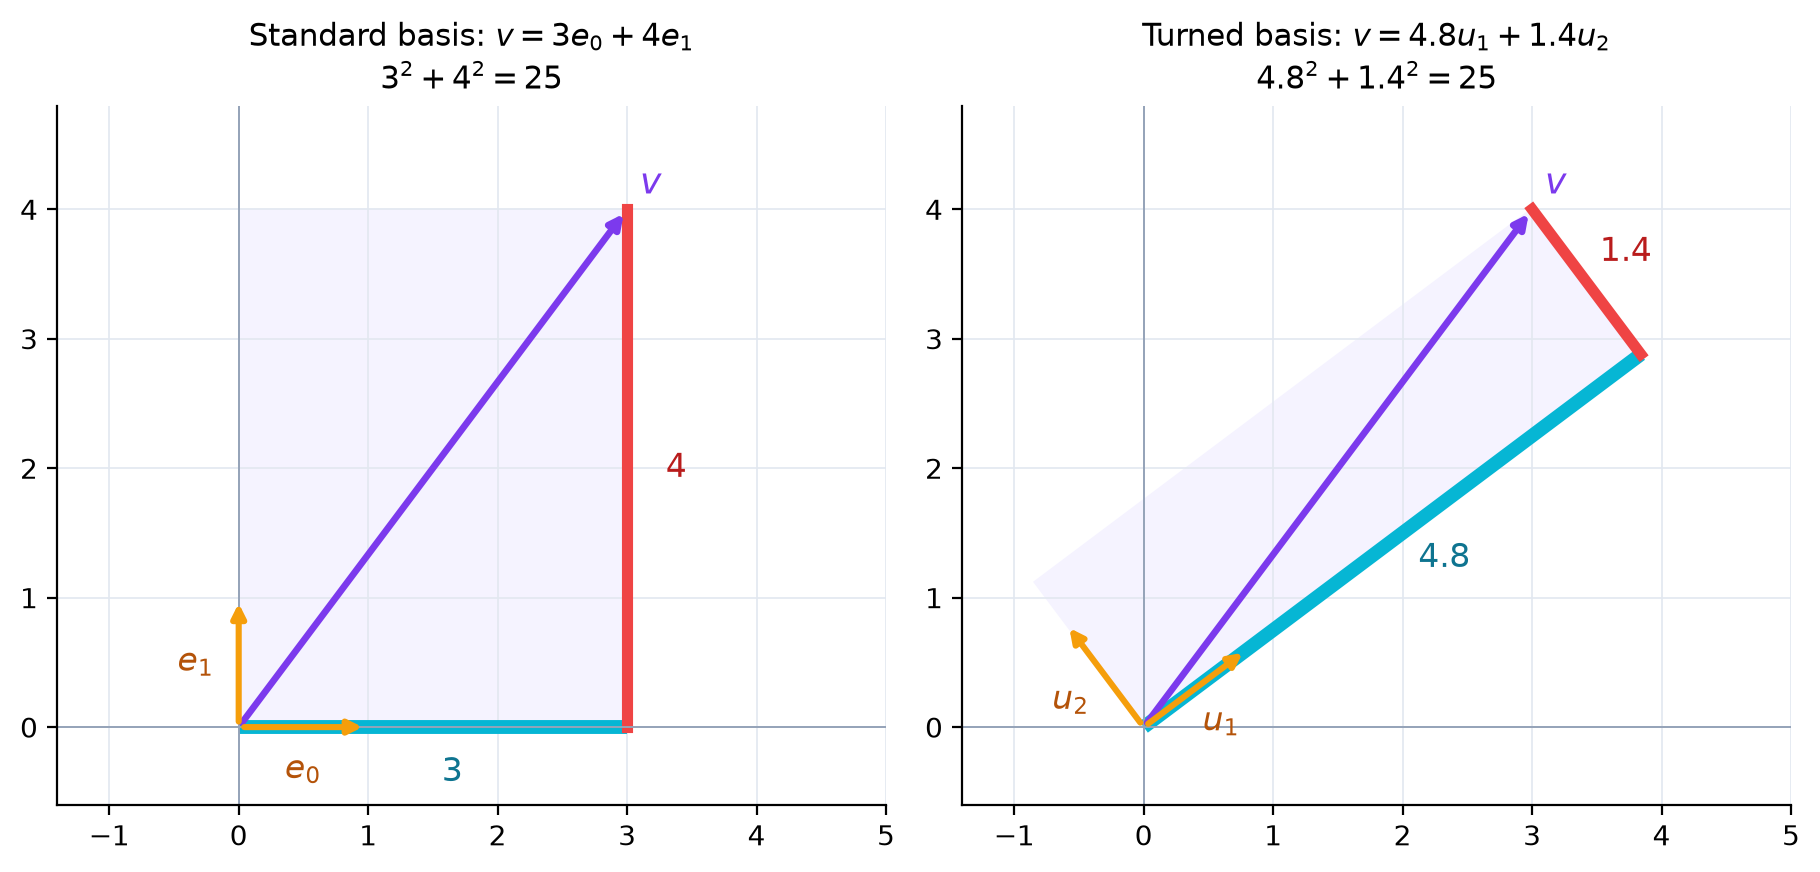

In [3]:
_show_mpl(_lessonfigs.parseval_two_bases())

*One arrow, two orthonormal bases. In the standard basis $v = (3, 4)$; in the turned basis $u_1 = (0.8, 0.6)$, $u_2 = (-0.6, 0.8)$ its coordinates are the shadows $4.8$ and $1.4$. Both pairs satisfy $3^2 + 4^2 = 4.8^2 + 1.4^2 = 25$.*

:::{warning} When is a squared overlap a probability?
In quantum theory, if $\psi$ is a **normalized** state vector and $e_1, \dots, e_n$ is the **orthonormal** basis of a measurement, the outcome $k$ has probability $|\langle e_k, \psi\rangle|^2$; Parseval guarantees these add to 1. Without normalization, or for vectors that are not orthonormal, squared overlaps need not add to 1 and are not probabilities. The physical rule is a postulate introduced in Level 5, not a consequence of the algebra here [@preskill].
:::

NumPy computes everything in this lesson. `np.dot` is the plain sum of products; `np.vdot` conjugates its first argument and is the inner product of [](#eq-l3-02-inner). The last loop tests Cauchy-Schwarz on 1000 random complex vectors.


In [4]:
import numpy as np

# real vectors: length, normalization, shadow (projection) on a unit vector
v = np.array([3.0, 4.0])
u = np.array([0.8, 0.6])                      # a unit vector
norm_v = np.linalg.norm(v)
print('||v|| =', norm_v, '  v/||v|| =', v / norm_v)
shadow = np.dot(u, v)                         # = ||v|| cos(angle)
p = shadow * u                                # projection of v on the line of u
r = v - p                                     # what is left over
print('<u, v> =', round(shadow, 6), ' projection', p.round(4), ' residual', r.round(4))
print('residual is orthogonal to u:', round(float(np.dot(u, r)), 12))
print('Pythagoras 4.8^2 + 1.4^2 =', round(shadow**2 + np.dot(r, r), 10))
angle = np.degrees(np.arccos(shadow / (np.linalg.norm(u) * norm_v)))
print('angle between u and v (degrees):', round(angle, 2))

# complex vectors: np.vdot conjugates its FIRST argument
w = np.array([1, 1j])
print('naive sum of squares of (1, i):', np.sum(w * w), '  <w, w> =', np.vdot(w, w))
a, b = np.array([1, 1j]), np.array([1j, 1])
print('<a, b> =', np.vdot(a, b), '  plain dot =', np.dot(a, b), '  <b, a> =', np.vdot(b, a))

# orthonormal basis expansion (Parseval) for the worked example psi = (1 + i, 1)/sqrt(3)
psi = np.array([1 + 1j, 1]) / np.sqrt(3)
plus, minus = np.array([1, 1]) / np.sqrt(2), np.array([1, -1]) / np.sqrt(2)
c_plus, c_minus = np.vdot(plus, psi), np.vdot(minus, psi)
print('|<+, psi>|^2 =', round(abs(c_plus)**2, 6), '  |<-, psi>|^2 =', round(abs(c_minus)**2, 6))
assert abs(abs(c_plus)**2 - 5/6) < 1e-12 and abs(abs(c_minus)**2 - 1/6) < 1e-12
assert np.allclose(c_plus * plus + c_minus * minus, psi)

# Cauchy-Schwarz on random complex vectors (seeded)
rng = np.random.default_rng(7)
worst = 0.0
for _ in range(1000):
    x = rng.normal(size=4) + 1j * rng.normal(size=4)
    y = rng.normal(size=4) + 1j * rng.normal(size=4)
    worst = max(worst, abs(np.vdot(x, y)) / (np.linalg.norm(x) * np.linalg.norm(y)))
print('largest |<x,y>| / (||x|| ||y||) in 1000 random trials:', round(worst, 4), '(never above 1)')

||v|| = 5.0   v/||v|| = [0.6 0.8]
<u, v> = 4.8  projection [3.84 2.88]  residual [-0.84  1.12]
residual is orthogonal to u: -0.0
Pythagoras 4.8^2 + 1.4^2 = 25.0
angle between u and v (degrees): 16.26
naive sum of squares of (1, i): 0j   <w, w> = (2+0j)
<a, b> = 0j   plain dot = 2j   <b, a> = 0j
|<+, psi>|^2 = 0.833333   |<-, psi>|^2 = 0.166667


largest |<x,y>| / (||x|| ||y||) in 1000 random trials: 0.9421 (never above 1)


## Worked example

:::{admonition} A complex state in two bases
:class: tip

Let $\psi = \frac{1}{\sqrt3}(1 + i,\ 1)$. Check that $\psi$ is normalized, compute its overlaps with $e_\pm = \frac{1}{\sqrt2}(1, \pm 1)$, and verify Parseval.

1. Norm: $\|\psi\|^2 = \frac{1}{3}\left(|1 + i|^2 + |1|^2\right) = \frac{1}{3}(2 + 1) = 1$. Note $|1 + i|^2 = (1 + i)(1 - i) = 2$, not $(1 + i)^2 = 2i$.
2. Overlap with $e_+$: the entries of $e_+$ are real, so conjugating changes nothing: $\langle e_+, \psi\rangle = \frac{1}{\sqrt6}\left((1 + i) + 1\right) = \frac{2 + i}{\sqrt6}$, and $|\langle e_+, \psi\rangle|^2 = \frac{4 + 1}{6} = \frac56$.
3. Overlap with $e_-$: $\langle e_-, \psi\rangle = \frac{1}{\sqrt6}\left((1 + i) - 1\right) = \frac{i}{\sqrt6}$, and $|\langle e_-, \psi\rangle|^2 = \frac16$.
4. Parseval: $\frac56 + \frac16 = 1 = \|\psi\|^2$. Reconstruction: $\frac{2 + i}{\sqrt6}\,e_+ + \frac{i}{\sqrt6}\,e_- = \frac{1}{\sqrt{12}}\left(2 + 2i,\ 2\right) = \frac{1}{\sqrt3}(1 + i, 1) = \psi$.

**Result.** $\psi$ is a unit vector with squared overlaps $5/6$ and $1/6$ on $e_+$ and $e_-$. If $\psi$ is a qubit state and $\{e_+, e_-\}$ the measurement basis, these are the outcome probabilities.
:::

## Exercises

**1. (Core)** Normalize $v = (1, 1)$. Compute the squared overlap of the result with $e_1 = (0, 1)$.

:::{dropdown} Solution
$\|v\| = \sqrt{1 + 1} = \sqrt2$, so $\hat v = (1/\sqrt2, 1/\sqrt2)$. Then $\langle e_1, \hat v\rangle = 0\cdot\frac{1}{\sqrt2} + 1\cdot\frac{1}{\sqrt2} = \frac{1}{\sqrt2}$ and the squared overlap is $\frac12$.
:::

**2. (Core)** Find the angle between $u = (2, -1, 2)$ and $v = (1, 2, 2)$ in $\mathbb{R}^3$.

:::{dropdown} Solution
$u\cdot v = 2 - 2 + 4 = 4$, $\|u\| = \sqrt{4 + 1 + 4} = 3$, $\|v\| = \sqrt{1 + 4 + 4} = 3$. So $\cos\theta = 4/9 \approx 0.444$ and $\theta = \arccos(4/9) \approx 63.61^\circ$.
:::

**3. (Stretch)** Let $a = (1, i)$ and $b = (i, 1)$. Compute $\langle a, b\rangle$, $\langle b, a\rangle$ and the plain sum of products $a_1 b_1 + a_2 b_2$. Are $a$ and $b$ orthogonal?

:::{dropdown} Solution
$\langle a, b\rangle = \bar 1\cdot i + \bar i \cdot 1 = i - i = 0$, and $\langle b, a\rangle = \overline{0} = 0$ (directly: $\bar i\cdot 1 + \bar 1\cdot i = -i + i = 0$). The plain sum is $i + i = 2i$. With the correct inner product $a$ and $b$ are orthogonal, even though the naive formula suggests otherwise.
:::

**4. (Stretch)** Express $v = (3, 4)$ in the orthonormal basis $u_1 = (0.8, 0.6)$, $u_2 = (-0.6, 0.8)$. Check that the basis is orthonormal and that Parseval holds.

:::{dropdown} Solution
$\|u_1\|^2 = 0.64 + 0.36 = 1$, $\|u_2\|^2 = 0.36 + 0.64 = 1$, $u_1\cdot u_2 = -0.48 + 0.48 = 0$. Coordinates: $u_1\cdot v = 2.4 + 2.4 = 4.8$ and $u_2\cdot v = -1.8 + 3.2 = 1.4$. So $v = 4.8\,u_1 + 1.4\,u_2$; check $4.8(0.8, 0.6) + 1.4(-0.6, 0.8) = (3.84 - 0.84,\ 2.88 + 1.12) = (3, 4)$. Parseval: $4.8^2 + 1.4^2 = 23.04 + 1.96 = 25 = 3^2 + 4^2$.
:::

**5. (Challenge)** Prove the triangle inequality $\|u + v\| \le \|u\| + \|v\|$ for $u, v \in \mathbb{C}^n$. When does equality hold?

:::{dropdown} Solution
$\|u + v\|^2 = \|u\|^2 + \|v\|^2 + \langle u, v\rangle + \langle v, u\rangle = \|u\|^2 + \|v\|^2 + 2\operatorname{Re}\langle u, v\rangle$. Since $\operatorname{Re} z \le |z|$ and by Cauchy-Schwarz $|\langle u, v\rangle| \le \|u\|\|v\|$, this is at most $\|u\|^2 + \|v\|^2 + 2\|u\|\|v\| = (\|u\| + \|v\|)^2$. Take square roots. Equality needs $\operatorname{Re}\langle u, v\rangle = \|u\|\|v\|$, which forces both $|\langle u, v\rangle| = \|u\|\|v\|$ (so one vector is a multiple of the other) and $\langle u, v\rangle$ real and non-negative: equality holds exactly when one vector is a non-negative real multiple of the other.
:::

**6. (Challenge)** Let $u$ be a unit vector in $\mathbb{C}^n$ and $v$ any vector. Show that $\|v - c\,u\|^2$ over complex $c$ is smallest at $c = \langle u, v\rangle$, with minimum value $\|v\|^2 - |\langle u, v\rangle|^2$. Evaluate it for $v = (3, 4)$ and $u = (0.8, 0.6)$.

:::{dropdown} Solution
Write $s = \langle u, v\rangle$. Expanding, $\|v - c u\|^2 = \|v\|^2 - \bar c\, s - c\,\bar s + |c|^2 = \|v\|^2 - |s|^2 + |c - s|^2$, since $|c - s|^2 = |c|^2 - c\bar s - \bar c s + |s|^2$. The last term is $\ge 0$ and vanishes only at $c = s$, so the minimum is $\|v\|^2 - |s|^2$. For the example $s = 4.8$ and the minimum is $25 - 23.04 = 1.96$, a distance of $1.4$: the length of the remainder in the projection picture.
:::

## Check your understanding

**1. What is the normalization of $v = (3, 4)$?**

- **A.** $(9/25, 16/25)$
- **B.** $(0.6, 0.8)$
- **C.** $(0.75, 1)$
- **D.** $(3/7, 4/7)$

:::{dropdown} Show the answer
**B. $(0.6, 0.8)$**

$\|v\| = \sqrt{9 + 16} = 5$, so $v/\|v\| = (3/5, 4/5) = (0.6, 0.8)$, which has norm $\sqrt{0.36 + 0.64} = 1$. Dividing by the sum of entries, 7, does not give a unit vector.
:::

**2. For $a = (1, i)$ and $b = (i, 1)$, what is $\langle a, b\rangle = \bar a_1 b_1 + \bar a_2 b_2$?**

- **A.** $2i$
- **B.** 0
- **C.** 2
- **D.** $-2i$

:::{dropdown} Show the answer
**B. 0**

$\bar 1\cdot i + \bar i\cdot 1 = i + (-i) = 0$, so the vectors are orthogonal. Forgetting the conjugate gives $2i$.
:::

**3. Real vectors $u$ and $v$ have $\|u\| = 1$ and $\|v\| = 5$. Which value is impossible for $u\cdot v$?**

- **A.** 4.8
- **B.** 5.2
- **C.** -5
- **D.** 0

:::{dropdown} Show the answer
**B. 5.2**

By Cauchy-Schwarz $|u\cdot v| \le \|u\|\|v\| = 5$: a shadow cannot be longer than the arrow. The values $-5$, $0$ and $4.8$ all occur for suitable directions.
:::

**4. What is $|1 + e^{i\varphi}|^2$ when $\varphi = \pi/2$?** *(Review of [L3-01](#lesson-l3-01))*

- **A.** $1 + i$
- **B.** 2
- **C.** 4
- **D.** 0

:::{dropdown} Show the answer
**B. 2**

$|1 + e^{i\varphi}|^2 = 2 + 2\cos\varphi$, and $\cos(\pi/2) = 0$, so the value is 2. Directly: $|1 + i|^2 = 1 + 1 = 2$.
:::

## Common misconceptions

- **"For complex vectors the inner product is the sum of products of entries, as for real vectors."** Without the conjugate, $(1, i)$ would have squared length $1 + i^2 = 0$. The inner product conjugates one slot, so $\langle v, v\rangle = \sum |v_j|^2$ is positive for every nonzero $v$.
- **"The overlap $\langle e_k, \psi\rangle$ is the probability of outcome $k$."** The overlap is a complex number and can be negative or imaginary. The probability is its squared modulus $|\langle e_k, \psi\rangle|^2$, and only for a normalized $\psi$ and an orthonormal measurement basis.
- **"An inner product of zero means one of the vectors is zero."** Zero inner product means orthogonal. $(3, 4)$ and $(0.8, -0.6)$ are both nonzero and $2.4 - 2.4 = 0$.
- **"Normalizing a vector changes where it points."** Normalizing divides by the positive number $\|v\|$, which only changes the length. The arrow slides along its own line onto the unit circle.

:::{caution} Scope and limits
This lesson works in finite dimensions with the standard inner product on $\mathbb{C}^n$, conjugate-linear in the first slot (the physics and NumPy convention). Other inner products exist (weighted sums, integrals for functions) and obey the same three axioms. The angle $\theta$ is defined only for real vectors; for complex vectors only $|\langle u, v\rangle|$ has an angle-like meaning. Reading squared overlaps as probabilities is a postulate of quantum theory that requires a normalized state and an orthonormal measurement basis; the algebra here does not by itself say anything about experiments.
:::

:::{seealso} Where this leads
Matrices in [L3-03](#lesson-l3-03) are judged by what they do to inner products: unitary matrices are exactly those that keep every $\langle u, v\rangle$. Tensor products in [L3-04](#lesson-l3-04) multiply inner products, $\langle a\otimes b, c\otimes d\rangle = \langle a, c\rangle\langle b, d\rangle$. In Level 5 the squared overlap $|\langle e_k, \psi\rangle|^2$ becomes the Born rule for measurement probabilities.
:::

:::{dropdown} For instructors

**Why this lesson.** Students arrive with the dot product as a formula; quantum information needs it as geometry (shadows, orthogonality) and as a complex construction (the conjugate). Cauchy-Schwarz is the first real proof in the course whose idea, subtract the projection and look at what is left, recurs in Gram-Schmidt, least squares and the Born rule [@mml; @nielsenchuang].

**Teaching notes.**

- Open with the $(1, i)$ puzzle and let students propose fixes before showing the conjugate; most will try absolute values of entries, which is the right idea.
- Use the projection explorer to ask for predictions: where is the shadow longest, zero, negative? Students should find $53.13^\circ$, $143.13^\circ$ and $233.13^\circ$ before moving the slider.
- Spend time on the proof of Cauchy-Schwarz. Draw the projection $p$ and remainder $r$ for real vectors, then point out that the algebra never used the picture, which is why it works in $\mathbb{C}^n$.
- Check the conjugate convention whenever students use software: `np.dot` does not conjugate, `np.vdot` does.

**Assessment.** The second stretch exercise (Parseval in a turned basis) and the worked example show whether students can expand in an orthonormal basis. The triangle-inequality challenge tests whether they can use Cauchy-Schwarz as a tool. The second check question catches the missing conjugate.

**Going further.** Derive the Gram-Schmidt process: given independent $v_1, v_2$, set $e_1 = v_1/\|v_1\|$ and $e_2 = (v_2 - \langle e_1, v_2\rangle e_1)/\|\cdot\|$. Apply it to $(1, 1, 0)$ and $(1, 0, 1)$. Mathematics for Machine Learning, chapter 3, develops inner products, angles and projections in this spirit [@mml].

:::

## References

This lesson draws on [@mml; @openstax_vectors; @nielsenchuang; @watrous; @preskill].

**Further reading.**

- [@mml]: Chapter 3 (analytic geometry): norms, inner products, angles, orthonormal bases and projections.
- [@nielsenchuang]: Section 2.1 states the inner product conventions used from Level 5 on.

**Next:** [L3-03 · Matrices as transformations](#lesson-l3-03)
